# Axion Ray SA Assignment Notebook
Author: Abhishek

This notebook covers:
- Task 1: Data Validation & Cleaning
- Task 2: Data Preparation & Integration
- Task 3: Exploratory Data Analysis (EDA)

Deliverables: cleaned datasets, tags, merged dataset, visualizations, and stakeholder summaries.

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import textwrap
from pathlib import Path

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

In [2]:
# Helper functions
def normalize_text(s):
    if pd.isna(s): return np.nan
    return re.sub(r"\s+", " ", str(s).strip())

def clean_categorical(series):
    return (series.astype(str).str.strip().str.upper()
            .replace({"NAN": np.nan, "NONE": np.nan, "": np.nan}))

def coerce_numeric(series):
    return pd.to_numeric(series, errors="coerce")

TAG_DICTIONARY = {
    "failure_conditions": ["INOP", "NOT WORKING", "PEELING", "STITCHING", "RUBBING"],
    "components": ["STEERING WHEEL", "HARNESS", "MODULE", "HORN"],
    "actions": ["REPLACED", "INSTALLED", "PROGRAMMED"]
}

def extract_tags(text):
    if pd.isna(text): return []
    t = str(text).upper()
    tags = []
    for group, keys in TAG_DICTIONARY.items():
        for k in keys:
            if k in t:
                tags.append(f"{group}:{k}")
    return sorted(set(tags))

## Task 1: Data Validation & Cleaning

In [3]:
# Load Task 1 dataset
df1 = pd.read_excel("SA - Data for Task 1 (1).xlsx")
print(df1.shape)
df1.head()

(100, 52)


,VIN,TRANSACTION_ID,CORRECTION_VERBATIM,CUSTOMER_VERBATIM,REPAIR_DATE,CAUSAL_PART_NM,GLOBAL_LABOR_CODE_DESCRIPTION,PLATFORM,BODY_STYLE,VPPC,...,TRANSMISSION_TRACE_NBR,SRC_TXN_ID,SRC_VER_NBR,TRANSACTION_CNTR,MEDIA_FLAG,VIN_MODL_DESGTR,LINE_SERIES,LAST_KNOWN_DELVRY_TYPE_CD,NON_CAUSAL_PART_QTY,SALES_REGION_CODE
0,3HCFDDE89SH220903,13021,REPLACED STEERING WHEEL NOW OKAY,STEERING WHEEL COMING APART,2024-01-02,WHEEL ASM-STRG *JET BLACK,Steering Wheel Replacement,Full-Size Trucks,Crew Cab,T1CCF,...,S2210121CNJX0941,2808908219,6,1,N,CF10543,1500,21.0,0,1
1,1HRFFEE8XSZ230636,13028,CHECKED - FOUND DTC'S U0229 - U1530 SET IN BCM...,CUSTOMER STATES HEATED STEERING WHEEL INOP,2024-01-03,MODULE ASM-STRG WHL HT CONT,Heated Steering Wheel Module Replacement,Full-Size Trucks,Crew Cab,T1CGF,...,R2210881CNJX0287,2808841910,6,1,Y,TF10543,1500,10.0,0,1
2,1HYKSMRK6SZ000990,13035,APPROVED 4.9(OLH) FOR ADDED DIAGNOSTICS WITH T...,OWNER REPORTS: THE SUPER CRUISE BAR ON THE STE...,2024-01-04,WHEEL ASM-STRG *BACKEN BLACKK,Steering Wheel Replacement,BEV,4 Door Utility,L233-LSOP,...,NaN,2809979441,4,1,Y,6MB26,Lux-1,10.0,0,1
3,3HCFDFEL3SH241701,13021,STEERING WHEEL REPLACEMENT,CUSTOMER STATES THE LETTERING AND FINISH ON TH...,2024-01-04,WHEEL ASM-STRG *JET BLACK,Steering Wheel Replacement,Full-Size Trucks,Crew Cab,T1CCF,...,S1210822CKJX0291,2808892288,6,1,Y,CF10543,1500,10.0,0,1
4,1HRFFHEL1RZ181474,13021,REPLACED STEERING MESSAGE NO LONGER DISPLAYED,C/S: CUSTOMER STATES THE SERVICE DRIVER ASSIST...,2024-01-05,WHEEL ASM-STRG *JET BLACK,Steering Wheel Replacement,Full-Size Trucks,Crew Cab,T1CGF,...,R2212982CKJX0282,2808901882,8,1,N,TF10543,1500,10.0,0,1


In [4]:
# Cleaning
df1["STATE"] = clean_categorical(df1["STATE"])
df1["BODY_STYLE"] = df1["BODY_STYLE"].str.title()
for col in ["REPORTING_COST","TOTALCOST","LBRCOST"]:
    df1[col] = coerce_numeric(df1[col])

# Generate tags
df1["Failure_Tags"] = df1["CUSTOMER_VERBATIM"].apply(extract_tags)
df1.head()

,VIN,TRANSACTION_ID,CORRECTION_VERBATIM,CUSTOMER_VERBATIM,REPAIR_DATE,CAUSAL_PART_NM,GLOBAL_LABOR_CODE_DESCRIPTION,PLATFORM,BODY_STYLE,VPPC,...,SRC_TXN_ID,SRC_VER_NBR,TRANSACTION_CNTR,MEDIA_FLAG,VIN_MODL_DESGTR,LINE_SERIES,LAST_KNOWN_DELVRY_TYPE_CD,NON_CAUSAL_PART_QTY,SALES_REGION_CODE,Failure_Tags
0,3HCFDDE89SH220903,13021,REPLACED STEERING WHEEL NOW OKAY,STEERING WHEEL COMING APART,2024-01-02,WHEEL ASM-STRG *JET BLACK,Steering Wheel Replacement,Full-Size Trucks,Crew Cab,T1CCF,...,2808908219,6,1,N,CF10543,1500,21.0,0,1,[components:STEERING WHEEL]
1,1HRFFEE8XSZ230636,13028,CHECKED - FOUND DTC'S U0229 - U1530 SET IN BCM...,CUSTOMER STATES HEATED STEERING WHEEL INOP,2024-01-03,MODULE ASM-STRG WHL HT CONT,Heated Steering Wheel Module Replacement,Full-Size Trucks,Crew Cab,T1CGF,...,2808841910,6,1,Y,TF10543,1500,10.0,0,1,"[components:STEERING WHEEL, failure_conditions..."
2,1HYKSMRK6SZ000990,13035,APPROVED 4.9(OLH) FOR ADDED DIAGNOSTICS WITH T...,OWNER REPORTS: THE SUPER CRUISE BAR ON THE STE...,2024-01-04,WHEEL ASM-STRG *BACKEN BLACKK,Steering Wheel Replacement,BEV,4 Door Utility,L233-LSOP,...,2809979441,4,1,Y,6MB26,Lux-1,10.0,0,1,[components:STEERING WHEEL]
3,3HCFDFEL3SH241701,13021,STEERING WHEEL REPLACEMENT,CUSTOMER STATES THE LETTERING AND FINISH ON TH...,2024-01-04,WHEEL ASM-STRG *JET BLACK,Steering Wheel Replacement,Full-Size Trucks,Crew Cab,T1CCF,...,2808892288,6,1,Y,CF10543,1500,10.0,0,1,[components:STEERING WHEEL]
4,1HRFFHEL1RZ181474,13021,REPLACED STEERING MESSAGE NO LONGER DISPLAYED,C/S: CUSTOMER STATES THE SERVICE DRIVER ASSIST...,2024-01-05,WHEEL ASM-STRG *JET BLACK,Steering Wheel Replacement,Full-Size Trucks,Crew Cab,T1CGF,...,2808901882,8,1,N,TF10543,1500,10.0,0,1,[]


### Visualizations (Task 1)

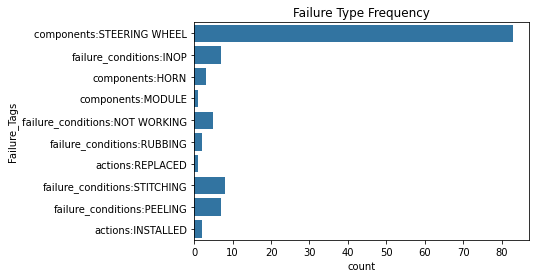

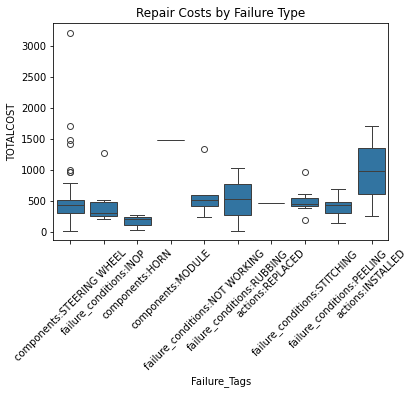

In [5]:


df_tags = df1.explode("Failure_Tags").reset_index(drop=True)

sns.countplot(y="Failure_Tags", data=df_tags)
plt.title("Failure Type Frequency")
plt.show()


sns.boxplot(x="Failure_Tags", y="TOTALCOST", data=df_tags)
plt.xticks(rotation=45)
plt.title("Repair Costs by Failure Type")
plt.show()




## Task 2: Data Preparation & Integration

In [6]:

# Load Task 2 dataset
df2 = pd.read_excel("SA - Data for Task 2.xlsx")
print("Task 2 shape:", df2.shape)


# Standardize column names
df1.columns = df1.columns.str.strip().str.upper()
df2.columns = df2.columns.str.strip().str.upper()

# Try VIN <-> SERIAL NUMBER
if "VIN" in df1.columns and "SERIAL NUMBER" in df2.columns:
    merged = pd.merge(df1, df2, left_on="VIN", right_on="SERIAL NUMBER", how="left")
elif "TRANSACTION_ID" in df1.columns and "PRIMARY KEY" in df2.columns:
    merged = pd.merge(df1, df2, left_on="TRANSACTION_ID", right_on="PRIMARY KEY", how="left")
else:
    raise KeyError("No suitable key found. Consider VIN ↔ SERIAL NUMBER or TRANSACTION_ID ↔ PRIMARY KEY.")

print("Merged shape:", merged.shape)
merged.head()



Task 2 shape: (500, 15)
Merged shape: (100, 68)


,VIN,TRANSACTION_ID,CORRECTION_VERBATIM,CUSTOMER_VERBATIM,REPAIR_DATE,CAUSAL_PART_NM,GLOBAL_LABOR_CODE_DESCRIPTION,PLATFORM,BODY_STYLE,VPPC,...,MODEL,PRODUCT CATEGORY,MODEL YEAR,SERIAL NUMBER,METER 1 READING,COMPLAINT,CAUSE,CORRECTION,FAILURE CONDITION - FAILURE COMPONENT,FIX CONDITION - FIX COMPONENT
0,3HCFDDE89SH220903,13021,REPLACED STEERING WHEEL NOW OKAY,STEERING WHEEL COMING APART,2024-01-02,WHEEL ASM-STRG *JET BLACK,Steering Wheel Replacement,Full-Size Trucks,Crew Cab,T1CCF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1HRFFEE8XSZ230636,13028,CHECKED - FOUND DTC'S U0229 - U1530 SET IN BCM...,CUSTOMER STATES HEATED STEERING WHEEL INOP,2024-01-03,MODULE ASM-STRG WHL HT CONT,Heated Steering Wheel Module Replacement,Full-Size Trucks,Crew Cab,T1CGF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1HYKSMRK6SZ000990,13035,APPROVED 4.9(OLH) FOR ADDED DIAGNOSTICS WITH T...,OWNER REPORTS: THE SUPER CRUISE BAR ON THE STE...,2024-01-04,WHEEL ASM-STRG *BACKEN BLACKK,Steering Wheel Replacement,BEV,4 Door Utility,L233-LSOP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3HCFDFEL3SH241701,13021,STEERING WHEEL REPLACEMENT,CUSTOMER STATES THE LETTERING AND FINISH ON TH...,2024-01-04,WHEEL ASM-STRG *JET BLACK,Steering Wheel Replacement,Full-Size Trucks,Crew Cab,T1CCF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1HRFFHEL1RZ181474,13021,REPLACED STEERING MESSAGE NO LONGER DISPLAYED,C/S: CUSTOMER STATES THE SERVICE DRIVER ASSIST...,2024-01-05,WHEEL ASM-STRG *JET BLACK,Steering Wheel Replacement,Full-Size Trucks,Crew Cab,T1CGF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Task 3: Exploratory Data Analysis (EDA)

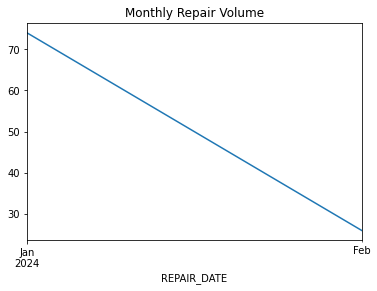

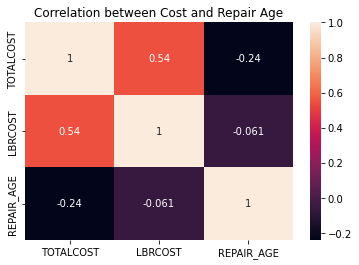

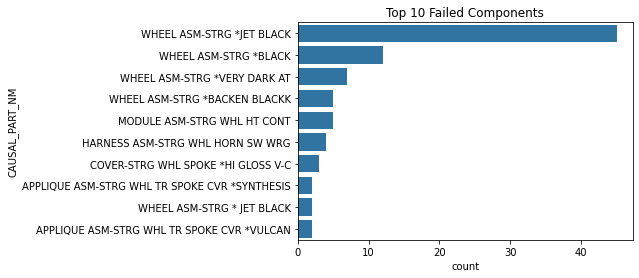

In [7]:
# Trend 1: Monthly repair volume
merged["REPAIR_DATE"] = pd.to_datetime(merged["REPAIR_DATE"], errors="coerce")
merged.groupby(merged["REPAIR_DATE"].dt.to_period("M"))["VIN"].count().plot(kind="line")
plt.title("Monthly Repair Volume")
plt.show()

# Trend 2: Correlation heatmap
sns.heatmap(merged[["TOTALCOST","LBRCOST","REPAIR_AGE"]].corr(), annot=True)
plt.title("Correlation between Cost and Repair Age")
plt.show()

# Trend 3: Failures by component
sns.countplot(y="CAUSAL_PART_NM", data=merged, order=merged["CAUSAL_PART_NM"].value_counts().index[:10])
plt.title("Top 10 Failed Components")
plt.show()